In [ ]:
# import libraries 
import os
import torch
import numpy as np
import random


from utils.preprocess import preprocess_simulation_input_data, preprocess_simulation_output_data, preprocess_experimental_backgroundwhite_rawfiles
from utils.preprocess import scale_latents
from utils.display import display_images_grid

from utils.config import SIMULATION_TEST_INPUT_FOLDER_2,SIMULATION_TEST_OUTPUT_FOLDER_2,SIMULATION_TEST_OUTPUT_FOLDER_TDB_2
from utils.config import LATENT_OUTPUT_SAVED, LATENT_OUTPUT_TDB_SAVED
from utils.config import SIMULATED_FOLDER, EXPERIMENTAL_FOLDER



### Reconstruction for Supplementary Figures 3, 4 and 5.

In [ ]:
"""Process 100 simulated and seed images """
# After processing the shape of the simulated images is 256x256, the shape of the seed is 32x32



sim_data=[]
seed_data=[]

sim_data=preprocess_simulation_output_data(SIMULATION_TEST_OUTPUT_FOLDER_2,0,100)
sim_data = [x[0] if isinstance(x, list) else x for x in sim_data]


seed_data=preprocess_simulation_input_data(SIMULATION_TEST_INPUT_FOLDER_2,0,100)
seed_data= [x[0] if isinstance(x, list) else x for x in seed_data]
# create_seed_data(top_crop_seed,bottom_crop_seed,left_crop_seed,right_crop_seed)

# this is done becuase the default matplotlib display normalizes weirdly when displaying binary grayscale images
seed_data= [np.repeat(x[..., None], 3, axis=-1) if isinstance(x, np.ndarray) and x.ndim==2 else x for x in seed_data]

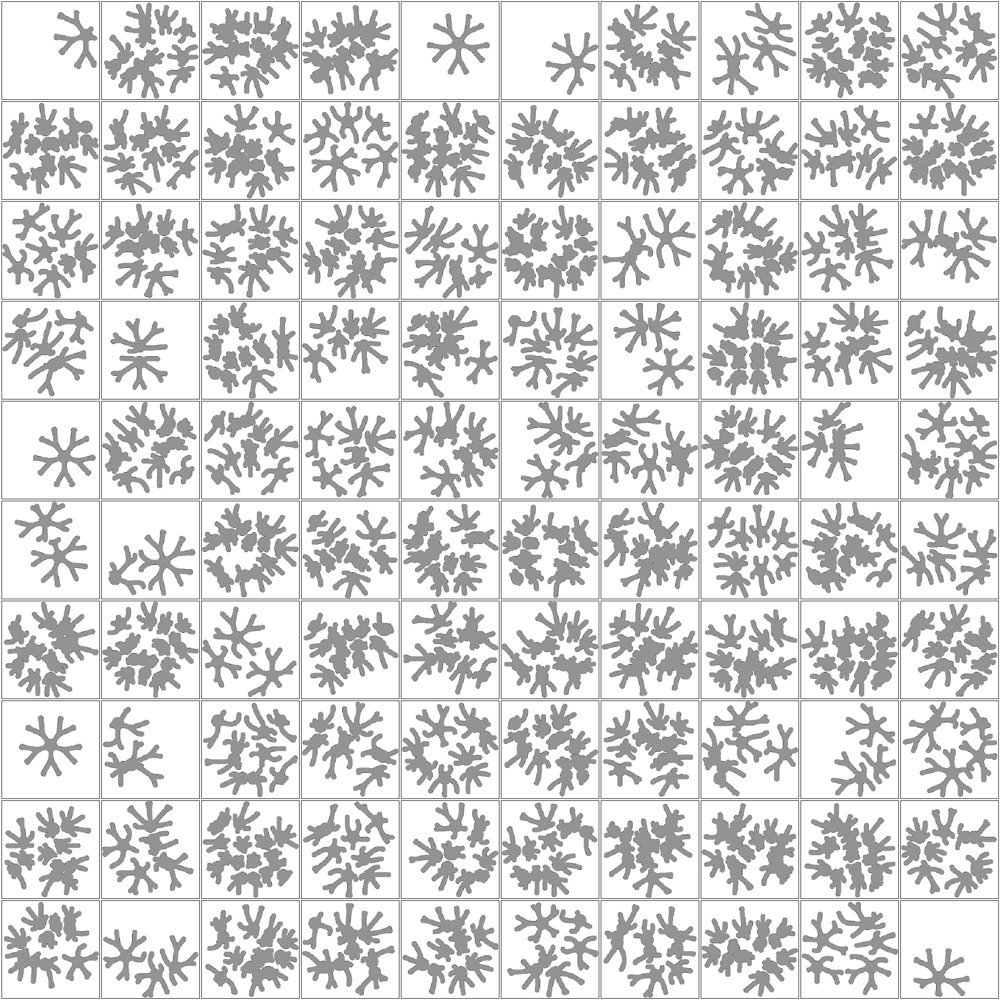

In [3]:
"""Display simulated images in a grid"""
display_images_grid(sim_data, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 4 — simulated patterns
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    sim_data, _GRID_OUT / 'SuppFig4_simulated_patterns_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig4_images.npz'),
)


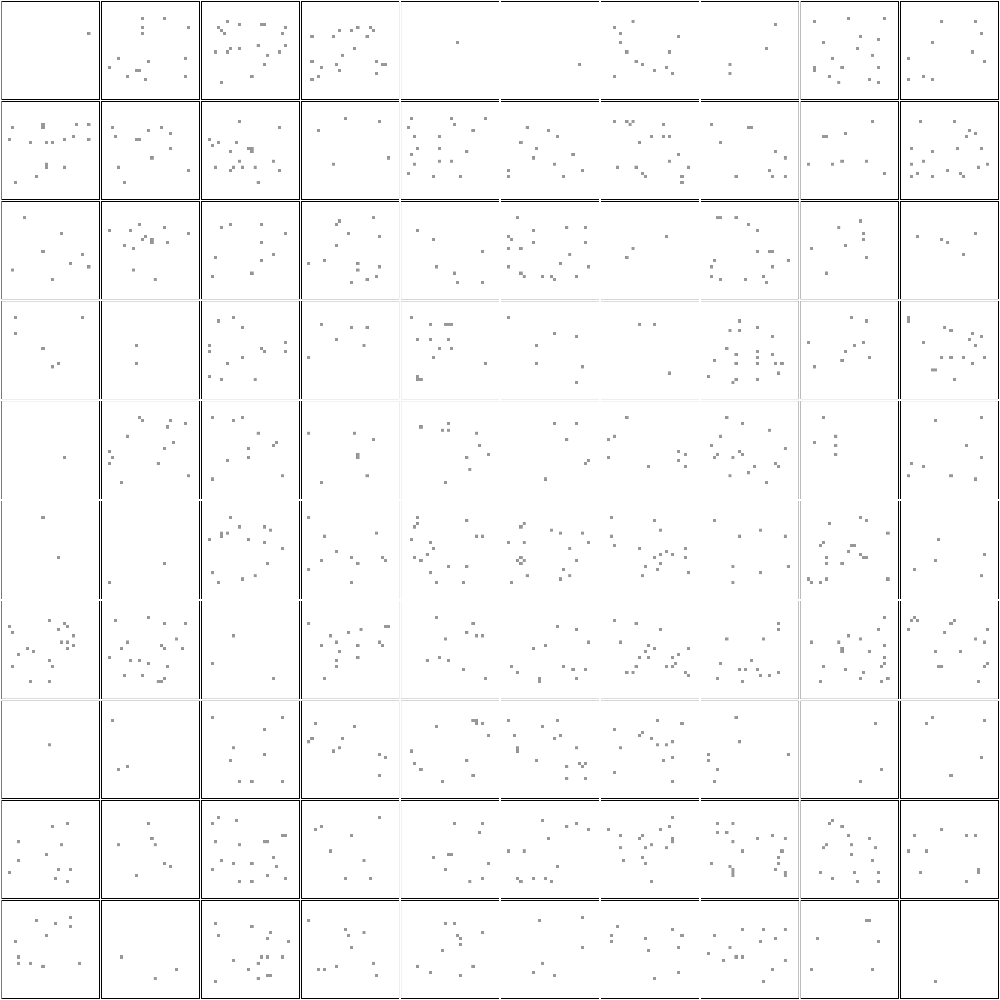

In [6]:
"""Display seed images in a grid"""
display_images_grid(seed_data, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 3 — seed configurations
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    seed_data, _GRID_OUT / 'SuppFig3_seed_configurations_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig3_images.npz'),
)


In [8]:
"""Load latents from pickle file and scale them for visualization"""

import pickle
# filepath='/hpc/group/youlab'
pickle_in=open(LATENT_OUTPUT_SAVED,"rb")
yprime=pickle.load(pickle_in)

# load the 100 specified latents
yprime=yprime[:100,:,:,:]

# convert to tensor
yprime=torch.Tensor(yprime)   # NOTE SHAPE IS torch.Size([100, 4, 32, 32])
yprime=yprime.float()

# scale latents for visualization
yprime_scaled=scale_latents(yprime)

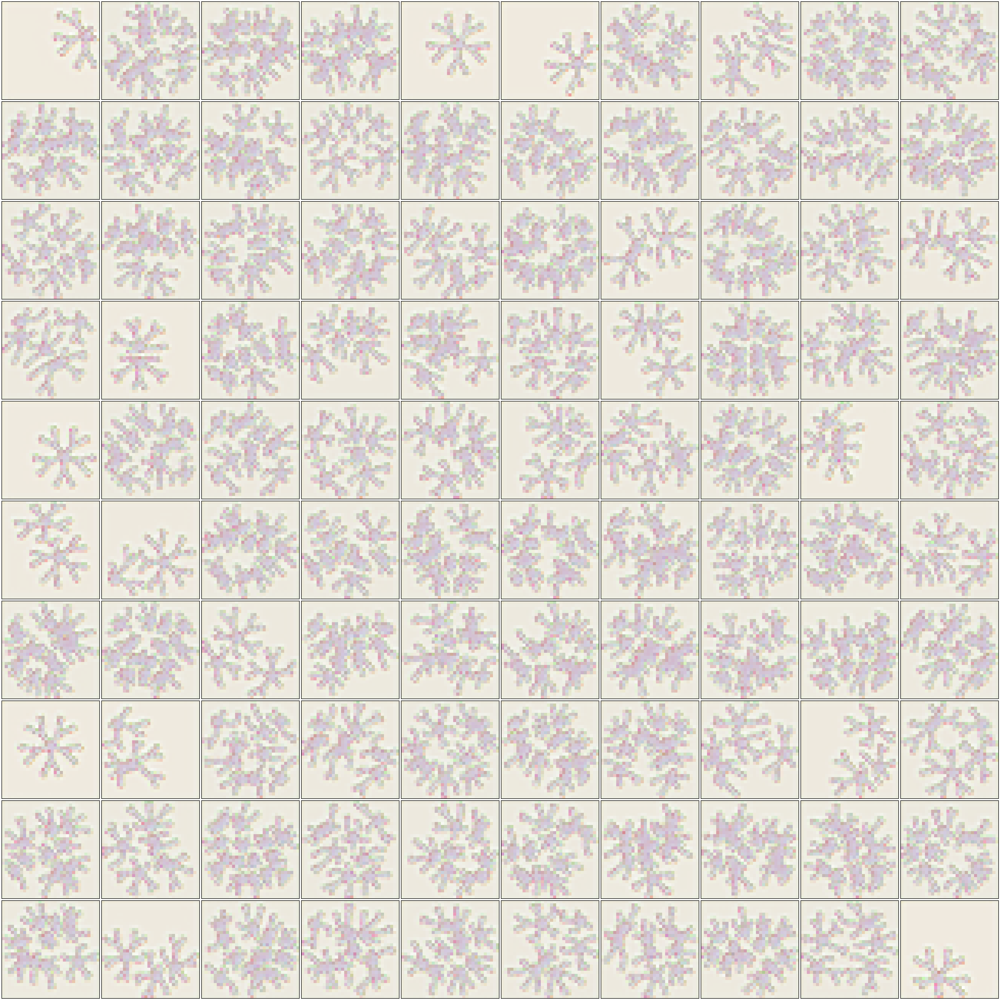

In [9]:
"""Display simulation latents in a grid"""
display_images_grid(yprime_scaled, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 5 — simulation latents
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    yprime_scaled, _GRID_OUT / 'SuppFig5_simulation_latents_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig5_images.npz'),
)


### This is for Supplementary Figures 8 and 9

In [11]:
"""Process 100 simulated and seed images """
# After processing the shape of the simulated images is 256x256, the shape of the seed is 32x32



sim_tdb_data=[]


sim_tdb_data=preprocess_simulation_output_data(SIMULATION_TEST_OUTPUT_FOLDER_TDB_2,0,100)
sim_tdb_data = [x[0] if isinstance(x, list) else x for x in sim_tdb_data]



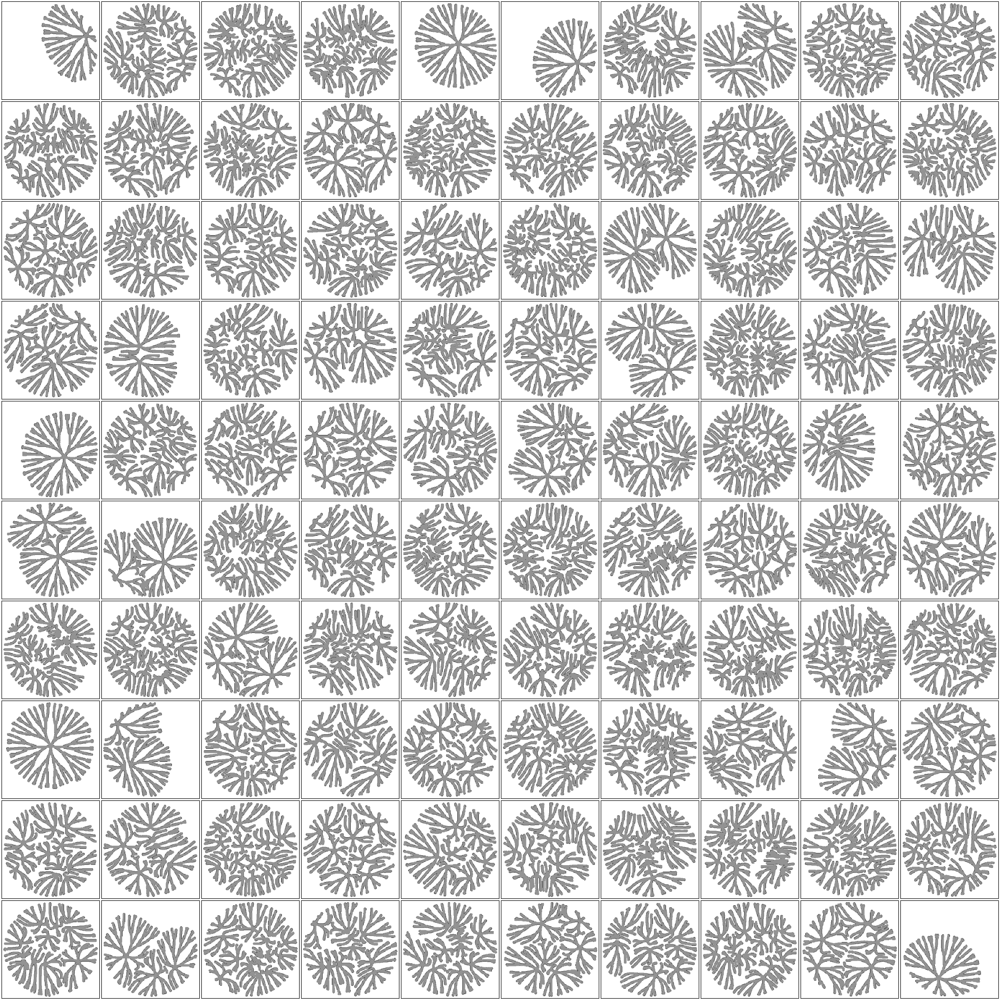

In [13]:
"""Display the thinner branch width, denser branches patterns(Sim2) in a grid"""
display_images_grid(sim_tdb_data, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 8 — thin dense patterns
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    sim_tdb_data, _GRID_OUT / 'SuppFig8_thin_dense_patterns_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig8_images.npz'),
)


In [15]:
"""Load latents from pickle file and scale them for visualization"""

import pickle
# filepath='/hpc/group/youlab'
pickle_in=open(LATENT_OUTPUT_TDB_SAVED,"rb")
yprime=pickle.load(pickle_in)

# load the 100 specified latents
yprime=yprime[:100,:,:,:]

# convert to tensor
yprime=torch.Tensor(yprime)   # NOTE SHAPE IS torch.Size([100, 4, 32, 32])
yprime=yprime.float()

# scale latents for visualization
yprime_scaled=scale_latents(yprime)

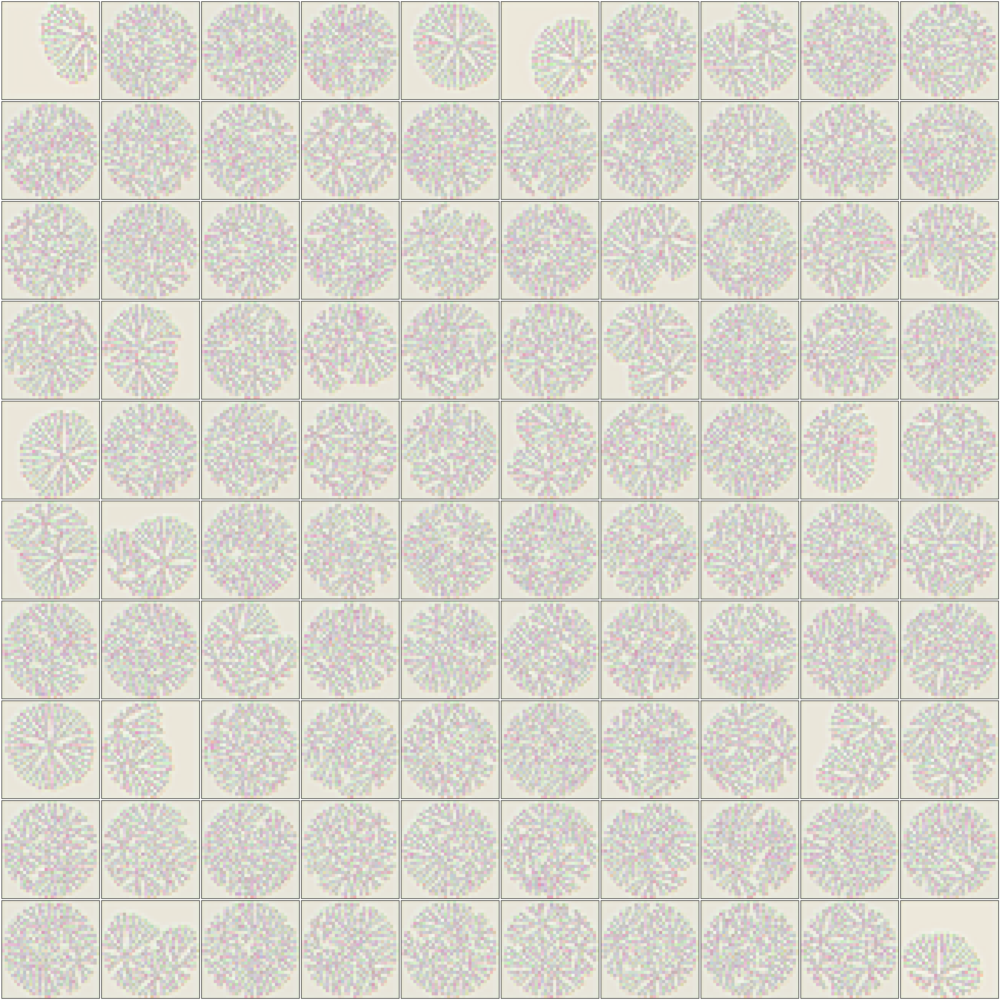

In [16]:
"""Display Sim2 latents in a grid"""
display_images_grid(yprime_scaled, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 9 — thin dense latents
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    yprime_scaled, _GRID_OUT / 'SuppFig9_thin_dense_latents_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig9_images.npz'),
)


### Reconstruction for Simulated and Experimental Grids used in Supplementary Figures 13 and 14

In [23]:
random.seed(42)  # For reproducibility
# simple logic
r= random.sample(os.listdir(SIMULATED_FOLDER), 100)  # Randomly select 100 images

In [29]:
"""Process 100 simulated and seed images """
# After processing the shape of the simulated images is 256x256, the shape of the seed is 32x32
sim_corrtoexp_data=[]


random.seed(42)  # For reproducibility
# simple logic
r= random.sample(os.listdir(SIMULATED_FOLDER), 100)  # Randomly select 100 images

sim_corrtoexp_data=preprocess_simulation_output_data(SIMULATED_FOLDER,0,len(r),img_filenames=r)
sim_corrtoexp_data = [x[0] if isinstance(x, list) else x for x in sim_corrtoexp_data]



In [ ]:
"""Process 100 simulated and seed images """
# After processing the shape of the simulated images is 256x256, the shape of the seed is 32x32
exp_data=[]

exp_data=preprocess_experimental_backgroundwhite_rawfiles(EXPERIMENTAL_FOLDER,0,len(r),img_filenames=r)
exp_data = [x[0] if isinstance(x, list) else x for x in exp_data]

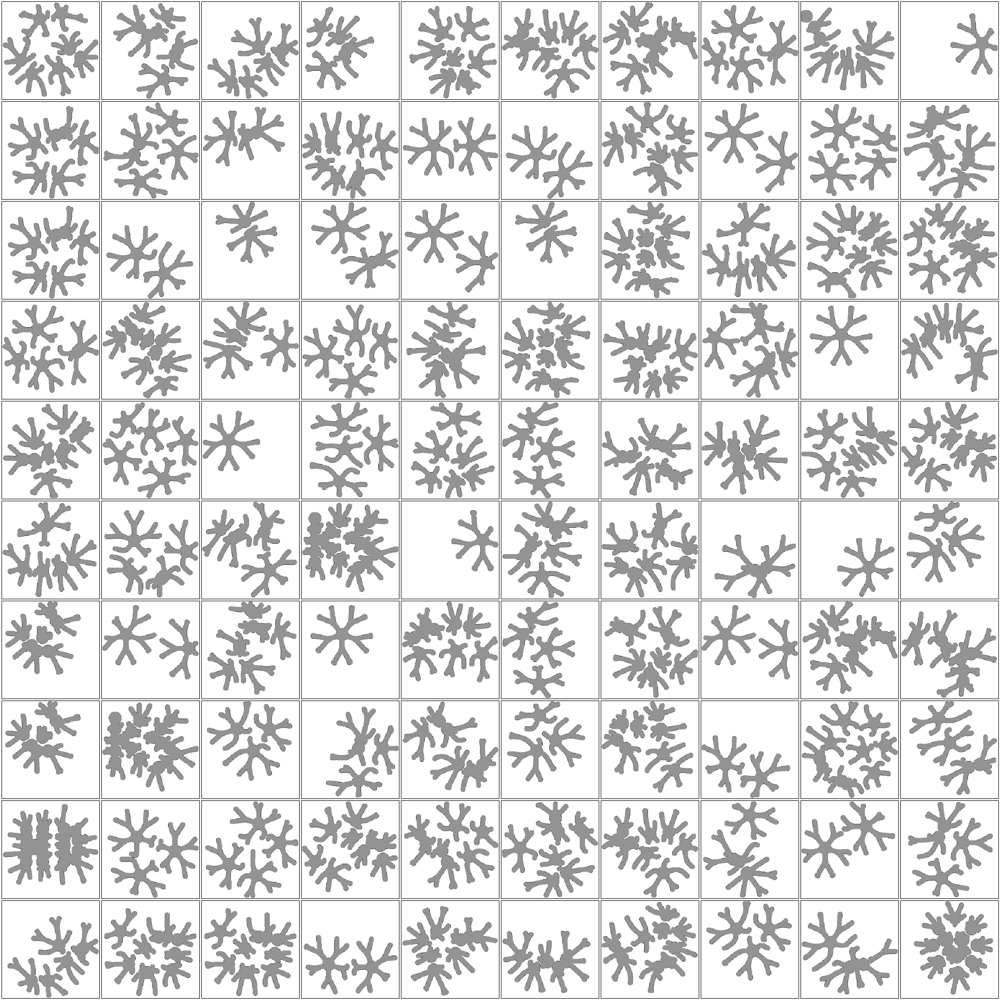

In [31]:
"""Display simulated images"""
display_images_grid(sim_corrtoexp_data, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 14 — experiment matched simulations
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    sim_corrtoexp_data, _GRID_OUT / 'SuppFig14_experiment_matched_simulations_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig14_images.npz'),
    filenames=r,
)


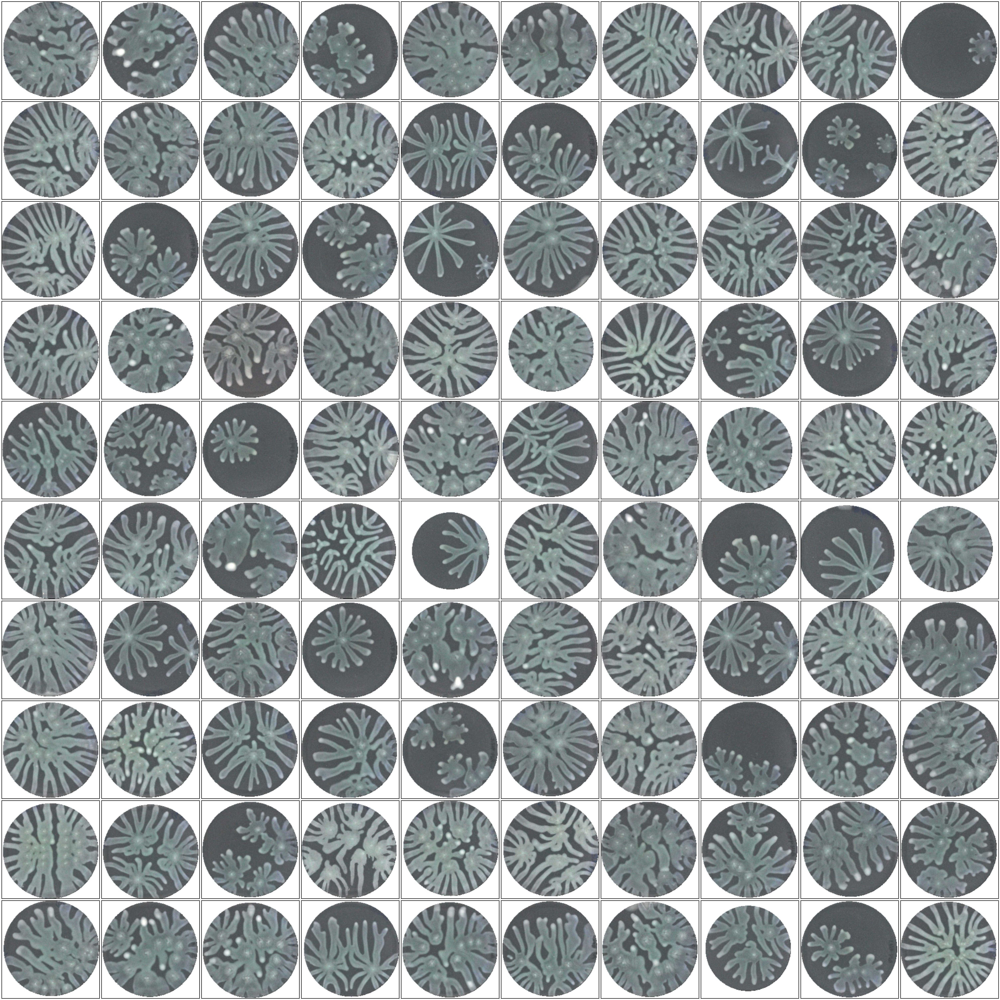

In [ ]:
"""Display experimental images"""
display_images_grid(exp_data, grid_size=(10, 10), figsize=(60, 60))

In [ ]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Image-object PDF export: Supplementary Fig. 13 — experimental patterns
# Run after the preceding source plot. Original image arrays are reused.
from pathlib import Path
import runpy as _grid_runpy
_GRID_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
_grid_save = vars(_figure_exports)['save_image_grid_pdf']
_GRID_OUT = _GRID_ROOT / 'seed_to_sim1_sim2_deterministic' / 'vector based plots'
_grid_save(
    exp_data, _GRID_OUT / 'SuppFig13_experimental_patterns_300dpi.pdf', dpi=300,
    figsize=(60, 60), grid_size=(10, 10),
    cache_path=_figure_source_path(_GRID_OUT / 'image grid source data' / 'SuppFig13_images.npz'),
    filenames=r,
)
